In [1]:
import os

folder_path = r"D:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT\Brain Tumor Data Set"
print(os.listdir(folder_path))


['Brain Tumor', 'Healthy', 'metadata.csv']


In [ ]:
!pip install numpy

In [ ]:

pip install numpy pandas matplotlib seaborn torch torchvision pillow scikit-learn tqdm torchsummary split-folders


In [4]:
# Import essential libraries
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns; sns.set(style='darkgrid')
import copy # A module that provides functions for creating copies of objects, useful for avoiding unintended modifications to variables.
import os # A module that provides a way to interact with the operating system, allowing for tasks such as file and directory manipulation.
import torch
from PIL import Image # A module from the Python Imaging Library (PIL) that provides functionality for opening, manipulating, and saving various image file formats.
from torch.utils.data import Dataset # A PyTorch class that represents a dataset and provides an interface for accessing and processing the data during training.
import torchvision
import torchvision.transforms as transforms # A module from the torchvision library that provides common image transformations, such as resizing, cropping, and normalization.
from torch.utils.data import random_split # A function from PyTorch that allows for randomly splitting a dataset into training and validation subsets.
from torch.optim.lr_scheduler import ReduceLROnPlateau # A PyTorch scheduler that adjusts the learning rate during training based on a specified metric, reducing it when the metric plateaus.
import torch.nn as nn # A module in PyTorch that provides classes for defining and building neural networks.
from torchvision import utils # A module from torchvision that contains utility functions for working with images, such as saving and visualizing them.
from torchvision.datasets import ImageFolder
import splitfolders
from torchsummary import summary
import torch.nn.functional as F
import pathlib
from sklearn.metrics import confusion_matrix, classification_report
import itertools # This import statement imports the itertools module, which provides functions for efficient looping and combining of iterables. It can be used for tasks such as generating combinations or permutations of elements.
from tqdm.notebook import trange, tqdm # These functions allow for the creation of progress bars to track the progress of loops or tasks.
from torch import optim
import warnings
warnings.filterwarnings('ignore')

In [ ]:
!pip install tabulate

In [15]:

# Define the correct file path (use raw string to handle backslashes)
file_path = r"D:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT\Brain Tumor Data Set\metadata.csv"

# Load the CSV file
labels_df = pd.read_csv(file_path)

# Show first 5 rows in a Markdown-style table
print(labels_df.head().to_markdown())


|    |   Unnamed: 0 | image           | class   | format   | mode   | shape         |
|---:|-------------:|:----------------|:--------|:---------|:-------|:--------------|
|  0 |            0 | Cancer (1).jpg  | tumor   | JPEG     | RGB    | (512, 512, 3) |
|  1 |            1 | Cancer (1).png  | tumor   | PNG      | L      | (300, 240)    |
|  2 |            2 | Cancer (1).tif  | tumor   | TIFF     | RGB    | (256, 256, 3) |
|  3 |            3 | Cancer (10).jpg | tumor   | JPEG     | RGB    | (512, 512, 3) |
|  4 |            4 | Cancer (10).tif | tumor   | TIFF     | RGB    | (256, 256, 3) |


In [16]:

folder_path = r"D:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT\Brain Tumor Data Set"
print(os.listdir(folder_path))


['Brain Tumor', 'Healthy', 'metadata.csv']


In [17]:
labels_df.shape

(4600, 6)

In [18]:

# Step 1: Original dataset path
data_dir = r"D:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT\Brain Tumor Data Set"
data_dir = pathlib.Path(data_dir)

# Step 2: Define output directory for split dataset
output_dir = r"D:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT\split_brain_dataset"

# Step 3: Perform split (80% train, 20% val)
splitfolders.ratio(data_dir, output=output_dir, seed=20, ratio=(0.8, 0.2))

# Step 4: Point to new dataset path
data_dir = pathlib.Path(output_dir)


Copying files: 4600 files [00:16, 278.15 files/s]


In [19]:
# define transformation
transform = transforms.Compose(
    [
        transforms.Resize((256,256)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(30),
        transforms.ToTensor(),
        transforms.Normalize(mean = [0.485, 0.456, 0.406],std = [0.229, 0.224, 0.225])
   ]
)

In [21]:
# Define an object of the custom dataset for the train and validation.
train_set = torchvision.datasets.ImageFolder(data_dir.joinpath("train"), transform=transform) 
train_set.transform
val_set = torchvision.datasets.ImageFolder(data_dir.joinpath("val"), transform=transform)
val_set.transform

Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-30.0, 30.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

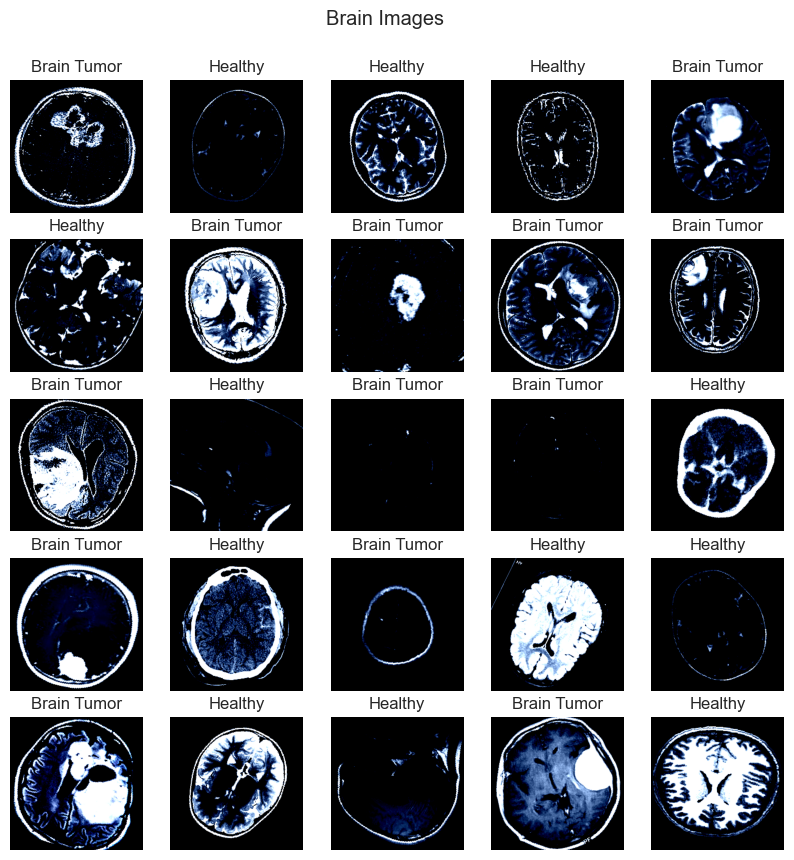

In [22]:

# Visualiztion some images from Train Set
CLA_label = {
    0 : 'Brain Tumor',
    1 : 'Healthy'
} 
figure = plt.figure(figsize=(10, 10))
cols, rows = 5, 5
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_set), size=(1,)).item()
    img, label = train_set[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(CLA_label[label])
    plt.axis("off")
    img_np = img.numpy().transpose((1, 2, 0))
    # Clip pixel values to [0, 1]
    img_valid_range = np.clip(img_np, 0, 1)
    plt.imshow(img_valid_range)
    plt.suptitle('Brain Images', y=0.95)
plt.show()

In [23]:
# import and load train, validation
batch_size = 64

train_loader = torch.utils.data.DataLoader(train_set, batch_size = batch_size, shuffle = True, num_workers = 2)
val_loader = torch.utils.data.DataLoader(val_set, batch_size = batch_size, shuffle = True, num_workers = 2)

In [24]:
# print shape for Training data and Validation data
for key, value in {'Training data': train_loader, "Validation data": val_loader}.items():
    for X, y in value:
        print(f"{key}:")
        print(f"Shape of X : {X.shape}")
        print(f"Shape of y: {y.shape} {y.dtype}\n")
        break


Training data:
Shape of X : torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([64]) torch.int64

Validation data:
Shape of X : torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([64]) torch.int64



#Define Brain Tumor Classifier

In [25]:
'''This function can be useful in determining the output size of a convolutional layer in a neural network,
given the input dimensions and the convolutional layer's parameters.'''

def findConv2dOutShape(hin,win,conv,pool=2):
    # get conv arguments
    kernel_size = conv.kernel_size
    stride=conv.stride
    padding=conv.padding
    dilation=conv.dilation

    hout=np.floor((hin+2*padding[0]-dilation[0]*(kernel_size[0]-1)-1)/stride[0]+1)
    wout=np.floor((win+2*padding[1]-dilation[1]*(kernel_size[1]-1)-1)/stride[1]+1)

    if pool:
        hout/=pool
        wout/=pool
    return int(hout),int(wout)

In [26]:
# Define Architecture For CNN_TUMOR Model
class CNN_TUMOR(nn.Module):
    
    # Network Initialisation
    def __init__(self, params):
        
        super(CNN_TUMOR, self).__init__()
    
        Cin,Hin,Win = params["shape_in"]
        init_f = params["initial_filters"] 
        num_fc1 = params["num_fc1"]  
        num_classes = params["num_classes"] 
        self.dropout_rate = params["dropout_rate"] 
        
        # Convolution Layers
        self.conv1 = nn.Conv2d(Cin, init_f, kernel_size=3)
        h,w=findConv2dOutShape(Hin,Win,self.conv1)
        self.conv2 = nn.Conv2d(init_f, 2*init_f, kernel_size=3)
        h,w=findConv2dOutShape(h,w,self.conv2)
        self.conv3 = nn.Conv2d(2*init_f, 4*init_f, kernel_size=3)
        h,w=findConv2dOutShape(h,w,self.conv3)
        self.conv4 = nn.Conv2d(4*init_f, 8*init_f, kernel_size=3)
        h,w=findConv2dOutShape(h,w,self.conv4)
        
        # compute the flatten size
        self.num_flatten=h*w*8*init_f
        self.fc1 = nn.Linear(self.num_flatten, num_fc1)
        self.fc2 = nn.Linear(num_fc1, num_classes)

    def forward(self,X):
        
        # Convolution & Pool Layers
        X = F.relu(self.conv1(X)); 
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv3(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv4(X))
        X = F.max_pool2d(X, 2, 2)
        X = X.view(-1, self.num_flatten)
        X = F.relu(self.fc1(X))
        X = F.dropout(X, self.dropout_rate)
        X = self.fc2(X)
        return F.log_softmax(X, dim=1)

In [27]:
params_model={
        "shape_in": (3,256,256), 
        "initial_filters": 8,    
        "num_fc1": 100,
        "dropout_rate": 0.25,
        "num_classes": 2}

# Create instantiation of Network class
cnn_model = CNN_TUMOR(params_model)

# define computation hardware approach (GPU/CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = cnn_model.to(device)

In [28]:
print(torch.cuda.is_available())  # True if GPU is accessible
print(torch.cuda.device_count())  # Number of GPUs
#print(torch.cuda.get_device_name(0))  # GPU model name


False
0


In [29]:
# Model Summary for CNN Model
summary(cnn_model, input_size=(3, 256, 256),device=device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 8, 254, 254]             224
            Conv2d-2         [-1, 16, 125, 125]           1,168
            Conv2d-3           [-1, 32, 60, 60]           4,640
            Conv2d-4           [-1, 64, 28, 28]          18,496
            Linear-5                  [-1, 100]       1,254,500
            Linear-6                    [-1, 2]             202
Total params: 1,279,230
Trainable params: 1,279,230
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.75
Forward/backward pass size (MB): 7.11
Params size (MB): 4.88
Estimated Total Size (MB): 12.74
----------------------------------------------------------------


In [30]:
loss_func = nn.NLLLoss(reduction="sum")

In [31]:
import torch
print(torch.__version__)


2.8.0+cpu


In [32]:
opt = optim.Adam(cnn_model.parameters(), lr=3e-4)
lr_scheduler = ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=20)

In [33]:
# Function to get the learning rate
def get_lr(opt):
    for param_group in opt.param_groups:
        return param_group['lr']

# Function to compute the loss value per batch of data
def loss_batch(loss_func, output, target, opt=None):
    
    loss = loss_func(output, target) # get loss
    pred = output.argmax(dim=1, keepdim=True) # Get Output Class
    metric_b=pred.eq(target.view_as(pred)).sum().item() # get performance metric
    
    if opt is not None:
        opt.zero_grad()
        loss.backward()
        opt.step()

    return loss.item(), metric_b

# Compute the loss value & performance metric for the entire dataset (epoch)
def loss_epoch(model,loss_func,dataset_dl,opt=None):
    
    run_loss=0.0 
    t_metric=0.0
    len_data=len(dataset_dl.dataset)

    # internal loop over dataset
    for xb, yb in dataset_dl:
        # move batch to device
        xb=xb.to(device)
        yb=yb.to(device)
        output=model(xb) # get model output
        loss_b,metric_b=loss_batch(loss_func, output, yb, opt) # get loss per batch
        run_loss+=loss_b        # update running loss

        if metric_b is not None: # update running metric
            t_metric+=metric_b    
    
    loss=run_loss/float(len_data)  # average loss value
    metric=t_metric/float(len_data) # average metric value
    
    return loss, metric

In [34]:

def Train_Val(model, params):
    
    # Get the parameters
    epochs = params["epochs"]
    loss_func = params["f_loss"]
    opt = params["optimiser"]
    train_dl = params["train"]
    val_dl = params["val"]
    lr_scheduler = params["lr_change"]
    weight_path = params["weight_path"]
    
    # Track loss and accuracy
    loss_history = {"train": [], "val": []}
    metric_history = {"train": [], "val": []}

    # Save best weights
    best_model_wts = copy.deepcopy(model.state_dict())
    best_loss = float('inf')

    # Training loop
    for epoch in tqdm(range(epochs)):
        
        current_lr = get_lr(opt)

        # Train
        model.train()
        train_loss, train_metric = loss_epoch(model, loss_func, train_dl, opt)
        loss_history["train"].append(train_loss)
        metric_history["train"].append(train_metric)

        # Validate
        model.eval()
        with torch.no_grad():
            val_loss, val_metric = loss_epoch(model, loss_func, val_dl)
        
        # Save best model
        if val_loss < best_loss:
            best_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), weight_path)
        
        # Store validation metrics
        loss_history["val"].append(val_loss)
        metric_history["val"].append(val_metric)

        # Learning rate scheduling
        lr_scheduler.step(val_loss)
        if current_lr != get_lr(opt):
            model.load_state_dict(best_model_wts)

    # Load best model before returning
    model.load_state_dict(best_model_wts)
    
    return model, loss_history, metric_history


In [ ]:
pip install ipywidgets


In [36]:
from tqdm import tqdm


In [37]:
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Step 1: Define optimizer
opt = Adam(cnn_model.parameters(), lr=3e-4)

# Step 2: Define learning rate scheduler (without 'verbose')
lr_scheduler = ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=20)

# Step 3: Define parameter dictionary
params_train = {
    "train": train_loader,
    "val": val_loader,
    "epochs": 60,
    "optimiser": opt,
    "lr_change": lr_scheduler,
    "f_loss": nn.NLLLoss(reduction="sum"),
    "weight_path": "weights.pt"
}

# Step 4: Train and validate the model
cnn_model, loss_hist, metric_hist = Train_Val(cnn_model, params_train)


100%|██████████| 60/60 [59:33<00:00, 59.55s/it] 


<Axes: >

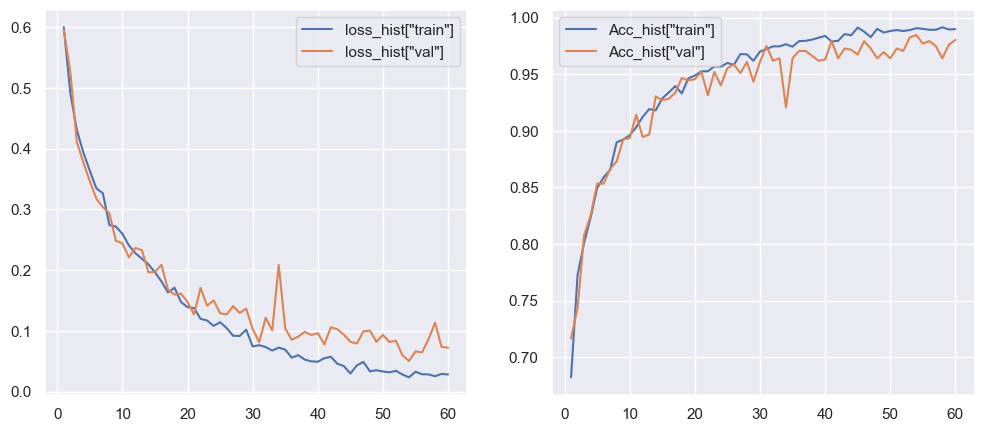

In [38]:
# Convergence History Plot
epochs=params_train["epochs"]
fig,ax = plt.subplots(1,2,figsize=(12,5))

sns.lineplot(x=[*range(1,epochs+1)],y=loss_hist["train"],ax=ax[0],label='loss_hist["train"]')
sns.lineplot(x=[*range(1,epochs+1)],y=loss_hist["val"],ax=ax[0],label='loss_hist["val"]')
sns.lineplot(x=[*range(1,epochs+1)],y=metric_hist["train"],ax=ax[1],label='Acc_hist["train"]')
sns.lineplot(x=[*range(1,epochs+1)],y=metric_hist["val"],ax=ax[1],label='Acc_hist["val"]')

In [39]:
# define function For Classification Report
def Ture_and_Pred(val_loader, model):
    i = 0
    y_true = []
    y_pred = []
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.numpy()
        outputs = model(images)
        _, pred = torch.max(outputs.data, 1)
        pred = pred.detach().cpu().numpy()
        
        y_true = np.append(y_true, labels)
        y_pred = np.append(y_pred, pred)
    
    return y_true, y_pred


# check confusion matrix for error analysis
y_true, y_pred = Ture_and_Pred(val_loader, cnn_model)

print(classification_report(y_true, y_pred), '\n\n')
cm = confusion_matrix(y_true, y_pred)

              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98       503
         1.0       0.98      0.97      0.97       418

    accuracy                           0.98       921
   macro avg       0.98      0.98      0.98       921
weighted avg       0.98      0.98      0.98       921
 




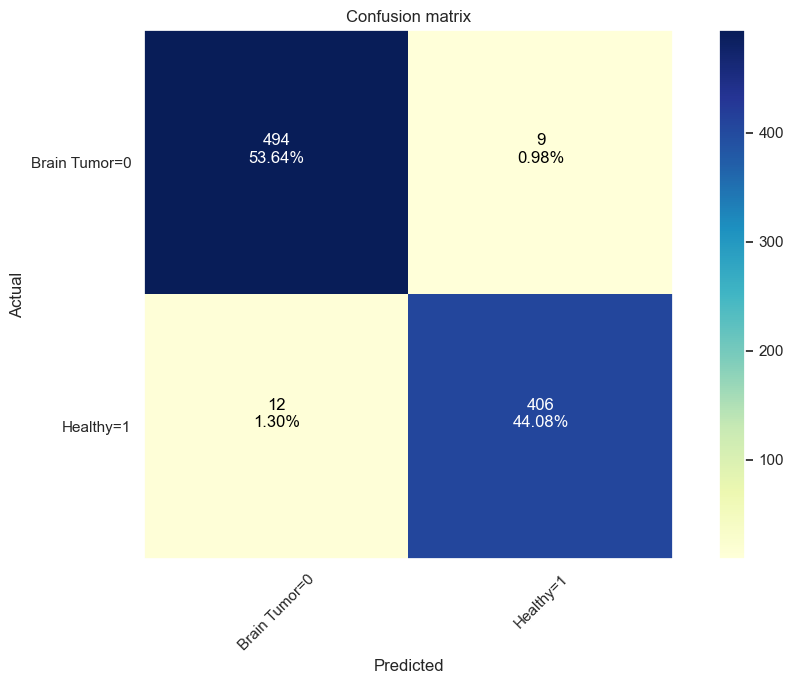

In [40]:
# Confusion Matrix Plotting Function
def show_confusion_matrix(cm, CLA_label, title='Confusion matrix', cmap=plt.cm.YlGnBu):
    
    plt.figure(figsize=(10,7))
    plt.grid(False)
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(CLA_label))

    plt.xticks(tick_marks, [f"{value}={key}" for key , value in CLA_label.items()], rotation=45)
    plt.yticks(tick_marks, [f"{value}={key}" for key , value in CLA_label.items()])

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, f"{cm[i,j]}\n{cm[i,j]/np.sum(cm)*100:.2f}%", horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

show_confusion_matrix(cm, CLA_label)

In [41]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

def True_Pred_Scores(val_loader, model):
    y_true = []
    y_pred = []
    y_scores = []

    model.eval()
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)  # log probabilities from log_softmax
            probs = torch.exp(outputs)  # convert log probs to probs
            tumor_scores = probs[:, 1]  # probability for class '1' (tumor)
            
            _, pred = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(pred.cpu().numpy())
            y_scores.extend(tumor_scores.cpu().numpy())
    
    return np.array(y_true), np.array(y_pred), np.array(y_scores)


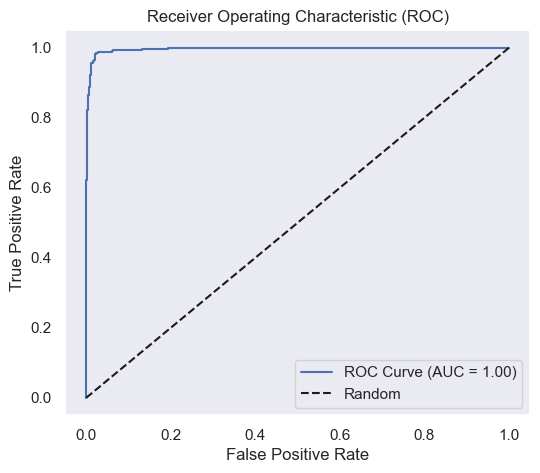

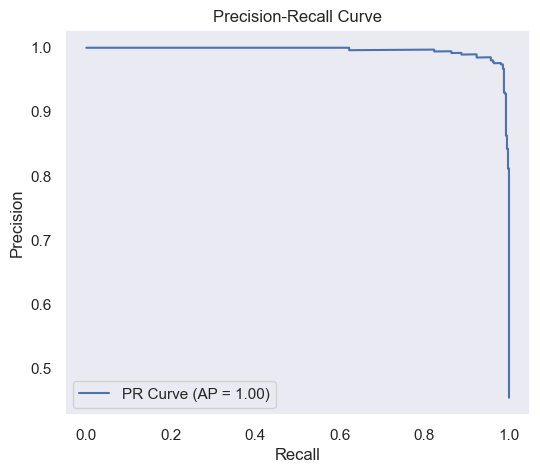

In [42]:
y_true, y_pred, y_scores = True_Pred_Scores(val_loader, cnn_model)

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend()
plt.grid()
plt.show()

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_true, y_scores)
ap = average_precision_score(y_true, y_scores)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f'PR Curve (AP = {ap:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid()
plt.show()


In [44]:
def get_misclassified_images(loader, model, dataset, cla_labels):
    misclassified_images = []
    model.eval()

    with torch.no_grad():
        for i, (images, labels) in enumerate(loader):
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for j in range(images.size(0)):
                if preds[j] != labels[j].to(device):
                    img_tensor = images[j].cpu()
                    img_label = labels[j].item()
                    img_pred = preds[j].cpu().item()
                    img_path, _ = dataset.samples[i * loader.batch_size + j]
                    
                    misclassified_images.append((img_tensor, img_label, img_pred, img_path))

    return misclassified_images


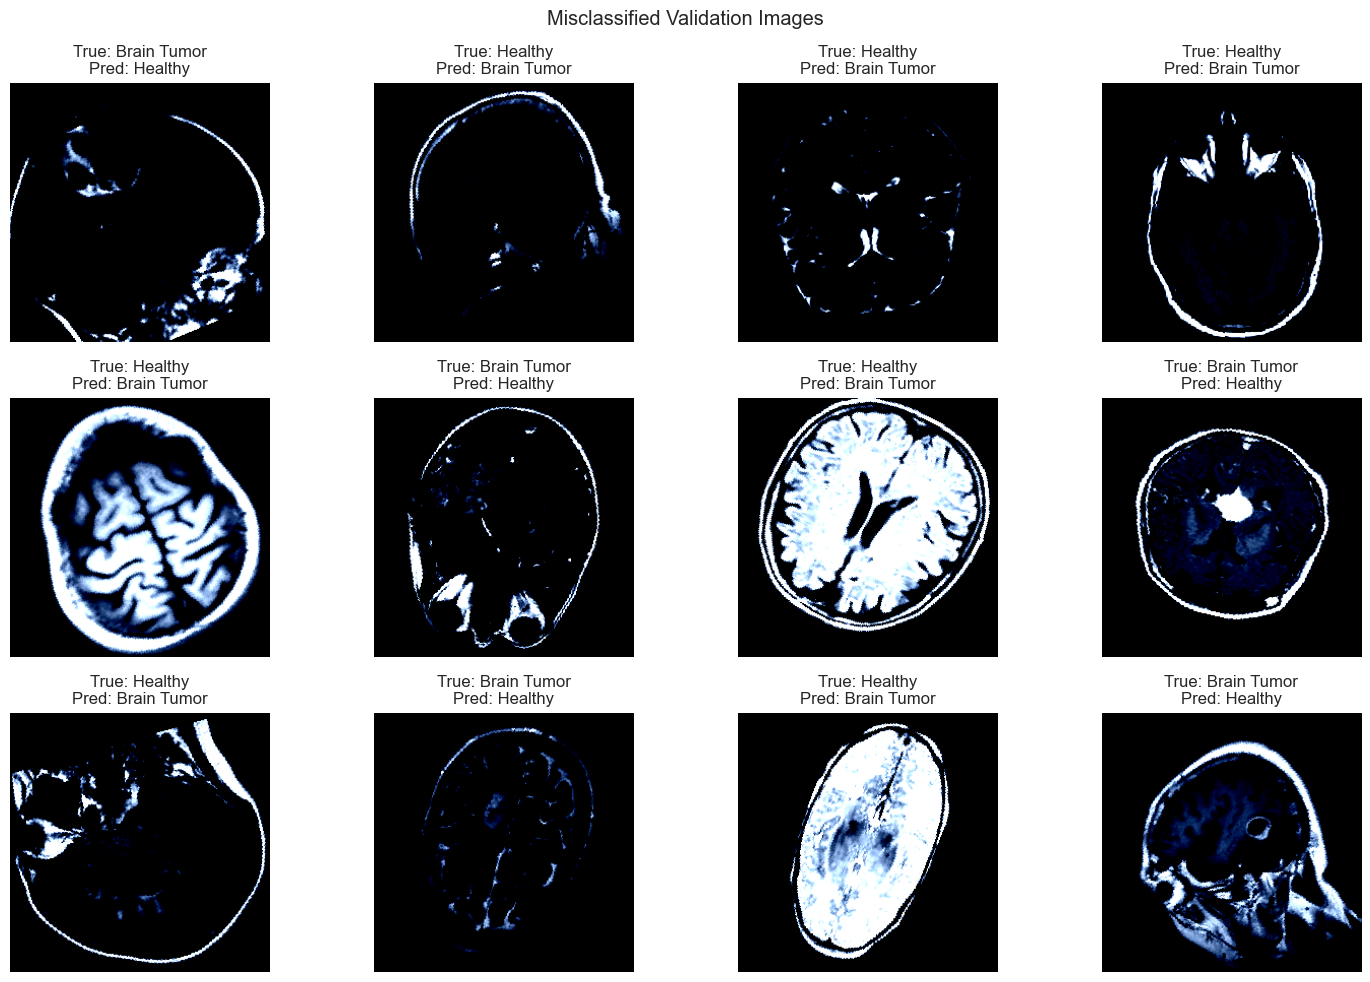

In [45]:
# Get misclassified images from validation set
misclassified = get_misclassified_images(val_loader, cnn_model, val_set, CLA_label)

# Visualize top 12 misclassified images
plt.figure(figsize=(15, 10))
for idx in range(min(12, len(misclassified))):
    img_tensor, true_label, pred_label, img_path = misclassified[idx]
    
    img_np = img_tensor.numpy().transpose((1, 2, 0))
    img_valid = np.clip(img_np, 0, 1)
    
    plt.subplot(3, 4, idx + 1)
    plt.imshow(img_valid)
    plt.title(f"True: {CLA_label[true_label]}\nPred: {CLA_label[pred_label]}")
    plt.axis('off')
plt.suptitle("Misclassified Validation Images")
plt.tight_layout()
plt.show()


In [46]:
torch.save(cnn_model.state_dict(), "cnn_brain.pt")


In [ ]:
torch.save(cnn_model, "Brain_Tumor_model.pt")

ResNet18

In [47]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [54]:
from torchvision import models

# Load pretrained ResNet18
resnet18 = models.resnet18(pretrained=True)

# Freeze all layers (optional if you want feature extraction only)
for param in resnet18.parameters():
    param.requires_grad = False


In [55]:
# Replace the final layer for binary classification
num_ftrs = resnet18.fc.in_features
resnet18.fc = nn.Sequential(
    nn.Linear(num_ftrs, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 2),
    nn.LogSoftmax(dim=1)
)

# Unfreeze last block if you want to fine-tune it
for param in resnet18.layer4.parameters():
    param.requires_grad = True

# Move model to device
resnet18 = resnet18.to(device)


In [56]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

opt = torch.optim.Adam(filter(lambda p: p.requires_grad, resnet18.parameters()), lr=1e-4)
lr_scheduler = ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=10)


In [57]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Define ImageNet-style transform for pretrained models like ResNet
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],  # mean
                         [0.229, 0.224, 0.225])  # std
])

# Correct paths to your dataset
train_path = r"D:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT\split_brain_dataset\train"
val_path   = r"D:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT\split_brain_dataset\val"

# Load datasets
train_dataset = datasets.ImageFolder(root=train_path, transform=transform)
val_dataset   = datasets.ImageFolder(root=val_path, transform=transform)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)


In [58]:
params_train_resnet = {
    "train": train_loader,
    "val": val_loader,
    "epochs": 30,
    "optimiser": opt,
    "lr_change": lr_scheduler,
    "f_loss": nn.NLLLoss(reduction="sum"),
    "weight_path": "resnet18_brain.pt"
}

resnet18, loss_hist_resnet, metric_hist_resnet = Train_Val(resnet18, params_train_resnet)


100%|██████████| 30/30 [2:27:34<00:00, 295.15s/it]  


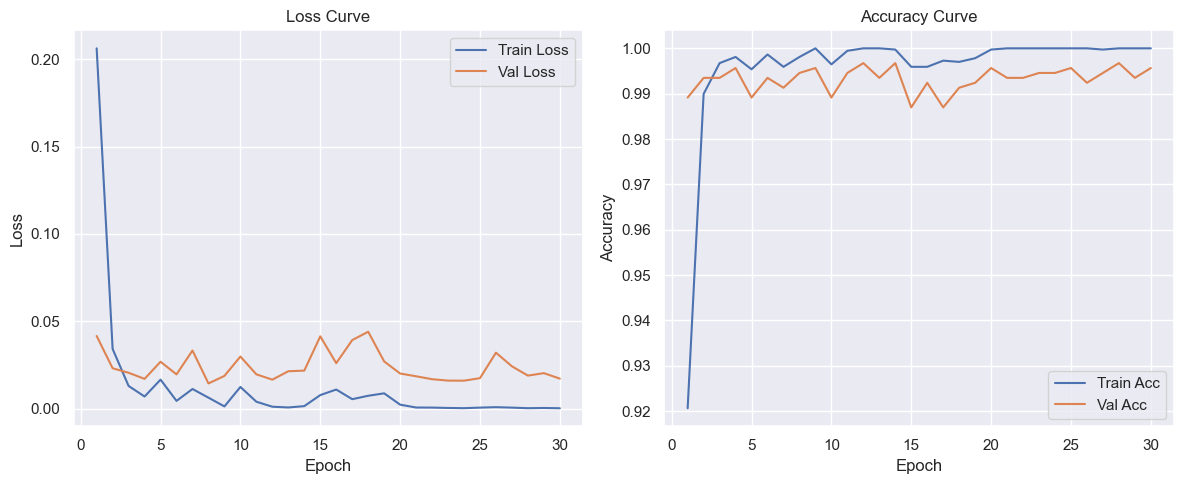

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns


# Plot loss and accuracy curves
epochs = params_train_resnet["epochs"]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.lineplot(x=range(1, epochs + 1), y=loss_hist_resnet["train"], ax=ax[0], label="Train Loss")
sns.lineplot(x=range(1, epochs + 1), y=loss_hist_resnet["val"], ax=ax[0], label="Val Loss")
ax[0].set_title("Loss Curve")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")

sns.lineplot(x=range(1, epochs + 1), y=metric_hist_resnet["train"], ax=ax[1], label="Train Acc")
sns.lineplot(x=range(1, epochs + 1), y=metric_hist_resnet["val"], ax=ax[1], label="Val Acc")
ax[1].set_title("Accuracy Curve")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")

plt.tight_layout()
plt.show()


In [60]:
import numpy as np

def True_Pred_Scores(loader, model):
    y_true = []
    y_pred = []
    y_scores = []

    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)  # Log probabilities (from LogSoftmax)
            probs = torch.exp(outputs)  # Convert log probs to normal probs
            tumor_probs = probs[:, 1]  # Class 1 = 'Brain Tumor'

            _, predicted = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            y_scores.extend(tumor_probs.cpu().numpy())

    return np.array(y_true), np.array(y_pred), np.array(y_scores)


y_true, y_pred, y_scores = True_Pred_Scores(val_loader, resnet18)


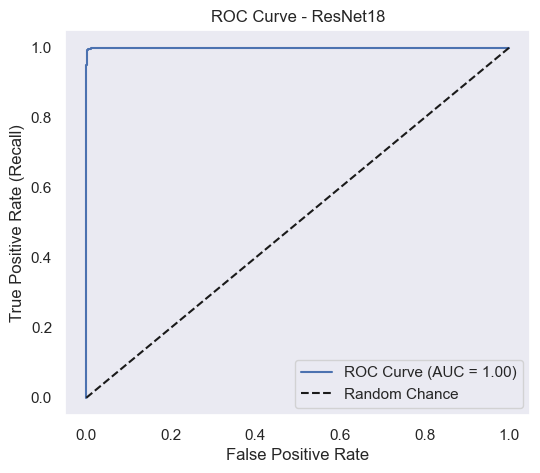

In [61]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - ResNet18')
plt.legend()
plt.grid()
plt.show()


In [62]:
from sklearn.metrics import classification_report, confusion_matrix

# Define a fixed version of your function for ResNet
def True_and_Pred(loader, model):
    y_true = []
    y_pred = []
    
    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels_np = labels.numpy()  # Still needed here
            
            outputs = model(images)
            _, preds = torch.max(outputs.data, 1)
            preds_np = preds.cpu().numpy()

            y_true.extend(labels_np)
            y_pred.extend(preds_np)

    return np.array(y_true), np.array(y_pred)

# Run it on your ResNet model
y_true_resnet, y_pred_resnet = True_and_Pred(val_loader, resnet18)

# Print classification report
print(classification_report(y_true_resnet, y_pred_resnet, target_names=["Brain Tumor", "Healthy"]))

# Get confusion matrix
cm_resnet = confusion_matrix(y_true_resnet, y_pred_resnet)


              precision    recall  f1-score   support

 Brain Tumor       0.99      1.00      1.00       503
     Healthy       1.00      0.99      0.99       418

    accuracy                           0.99       921
   macro avg       0.99      0.99      0.99       921
weighted avg       0.99      0.99      0.99       921



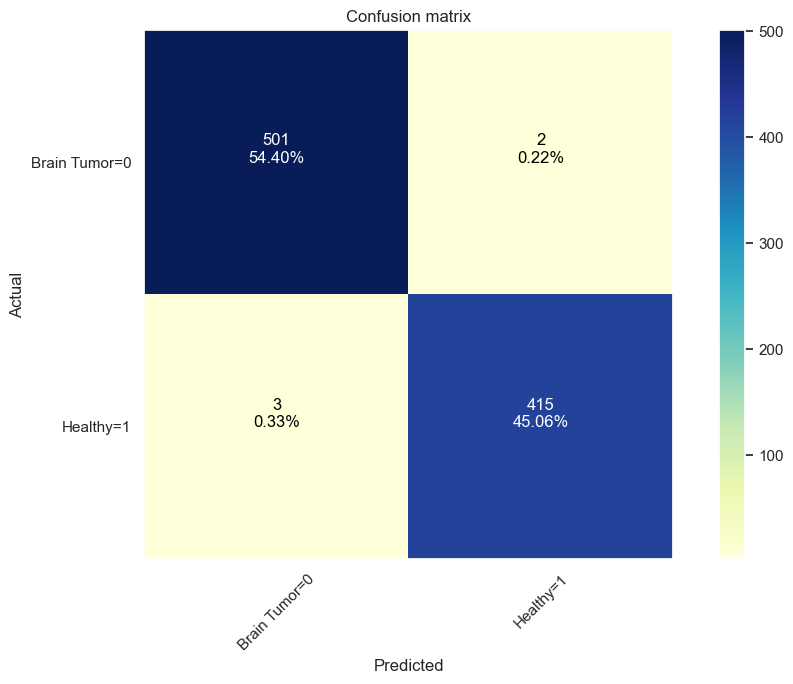

In [63]:
import itertools

# Confusion Matrix Plotting Function
def show_confusion_matrix(cm, CLA_label, title='Confusion matrix', cmap=plt.cm.YlGnBu):
    
    plt.figure(figsize=(10,7))
    plt.grid(False)
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(CLA_label))

    plt.xticks(tick_marks, [f"{value}={key}" for key , value in CLA_label.items()], rotation=45)
    plt.yticks(tick_marks, [f"{value}={key}" for key , value in CLA_label.items()])

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, f"{cm[i,j]}\n{cm[i,j]/np.sum(cm)*100:.2f}%", horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

show_confusion_matrix(cm_resnet, CLA_label)

In [64]:
def get_misclassified_images(loader, model, dataset, class_labels):
    misclassified = []

    model.eval()
    with torch.no_grad():
        for i, (images, labels) in enumerate(loader):
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for j in range(images.size(0)):
                true_label = labels[j].item()
                pred_label = preds[j].item()

                if true_label != pred_label:
                    img_tensor = images[j].cpu()
                    idx_in_dataset = i * loader.batch_size + j
                    if idx_in_dataset < len(dataset):
                        img_path, _ = dataset.samples[idx_in_dataset]
                    else:
                        img_path = "N/A"
                    
                    misclassified.append((img_tensor, true_label, pred_label, img_path))

    return misclassified


In [65]:
CLA_label = {
    0: "Brain Tumor",
    1: "Healthy"
}

misclassified = get_misclassified_images(val_loader, resnet18, val_dataset, CLA_label)


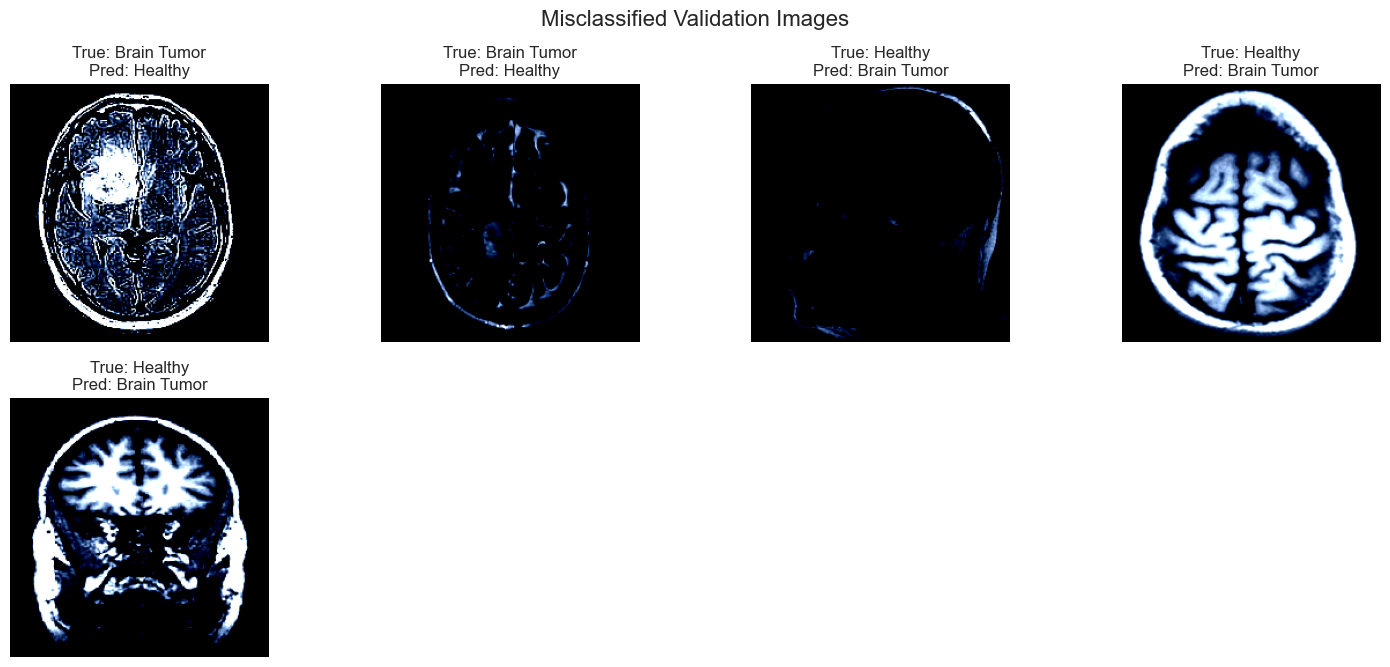

In [66]:
# Visualize first 12 misclassified images
plt.figure(figsize=(15, 10))
for idx in range(min(15, len(misclassified))):
    img_tensor, true_label, pred_label, img_path = misclassified[idx]

    img_np = img_tensor.numpy().transpose((1, 2, 0))
    img_np = np.clip(img_np, 0, 1)

    plt.subplot(3, 4, idx + 1)
    plt.imshow(img_np)
    plt.title(f"True: {CLA_label[true_label]}\nPred: {CLA_label[pred_label]}")
    plt.axis('off')

plt.suptitle("Misclassified Validation Images", fontsize=16)
plt.tight_layout()
plt.show()


In [69]:
torch.save(resnet18.state_dict(), "resnet18_brain.pt")


In [70]:
import os
print(os.getcwd())
print(os.listdir())


d:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT
['Brain Tumor Data Set', 'Brain_Tumor_Classification_Report.docx', 'BT project.ipynb', 'model trained', 'resnet18_brain.pt', 'split_brain_dataset', 'trial image.jpg', 'weights.pt']


In [76]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# --- CNN Metrics ---
y_true_cnn, y_pred_cnn, y_scores_cnn = True_Pred_Scores(val_loader, cnn_model)
acc_cnn = accuracy_score(y_true_cnn, y_pred_cnn)
f1_cnn = f1_score(y_true_cnn, y_pred_cnn)
precision_cnn = precision_score(y_true_cnn, y_pred_cnn)
recall_cnn = recall_score(y_true_cnn, y_pred_cnn)
auc_cnn = auc(*roc_curve(y_true_cnn, y_scores_cnn)[:2])
ap_cnn = average_precision_score(y_true_cnn, y_scores_cnn)

# --- ResNet18 Metrics ---
y_true_resnet, y_pred_resnet, y_scores_resnet = True_Pred_Scores(val_loader, resnet18)
acc_resnet = accuracy_score(y_true_resnet, y_pred_resnet)
f1_resnet = f1_score(y_true_resnet, y_pred_resnet)
precision_resnet = precision_score(y_true_resnet, y_pred_resnet)
recall_resnet = recall_score(y_true_resnet, y_pred_resnet)
auc_resnet = auc(*roc_curve(y_true_resnet, y_scores_resnet)[:2])
ap_resnet = average_precision_score(y_true_resnet, y_scores_resnet)

# --- Build DataFrame ---
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": ["CNN", "ResNet18"],
    "Accuracy": [acc_cnn, acc_resnet],
    "F1-Score": [f1_cnn, f1_resnet],
    "Precision": [precision_cnn, precision_resnet],
    "Recall (Sensitivity)": [recall_cnn, recall_resnet],
    "AUC (ROC)": [auc_cnn, auc_resnet],
    "Average Precision (PR)": [ap_cnn, ap_resnet]
})

# Display in notebook
from tabulate import tabulate
print(tabulate(comparison_df, headers='keys', tablefmt='github'))


RuntimeError: cannot register a hook on a tensor that doesn't require gradient

Add Grad-CAM for CNN & ResNet18

In [ ]:
pip install torchcam


In [73]:
from torchcam.methods import GradCAM
from torchcam.utils import overlay_mask
from torchvision.transforms.functional import to_pil_image
import matplotlib.pyplot as plt


In [75]:
cam_extractor_cnn = GradCAM(cnn_model, target_layer="conv4")


In [74]:
cam_extractor_resnet = GradCAM(resnet18, target_layer="layer4")


In [77]:
def show_gradcam(model, cam_extractor, dataset, index=0, class_labels=CLA_label):
    model.eval()

    # Get a single image and label
    img_tensor, label = dataset[index]
    input_tensor = img_tensor.unsqueeze(0).to(device)

    # Forward pass
    out = model(input_tensor)
    pred_class = out.argmax().item()

    # Extract CAM
    activation_map = cam_extractor(pred_class, out)[0].squeeze().cpu()

    # Overlay CAM on image
    result = overlay_mask(to_pil_image(img_tensor), to_pil_image(activation_map, mode='F'), alpha=0.5)

    # Plot
    plt.figure(figsize=(6, 6))
    plt.imshow(result)
    plt.title(f"True: {class_labels[label]}\nPred: {class_labels[pred_class]}")
    plt.axis('off')
    plt.show()

    # ✅ Updated cleanup
    cam_extractor.reset_hooks()


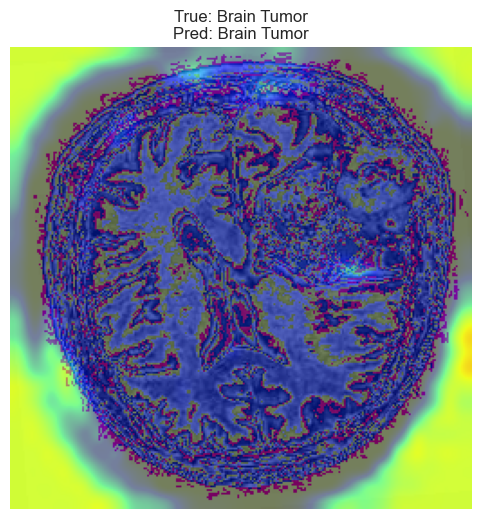

In [78]:
show_gradcam(cnn_model, cam_extractor_cnn, val_set, index=15)


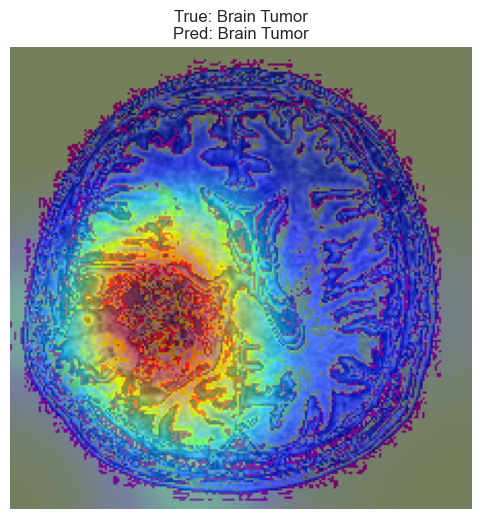

In [79]:
show_gradcam(resnet18, cam_extractor_resnet, val_dataset, index=15)


In [ ]:
pip install torchvision torch matplotlib scikit-learn tqdm


In [81]:
import torch
import torch.nn as nn
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np


In [82]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])


In [84]:
train_path = r"D:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT\split_brain_dataset\train"
val_path   = r"D:\AI Students Profile_RACE_Cyberium Labs\My project practice\BT\split_brain_dataset\val"

train_dataset = datasets.ImageFolder(train_path, transform=transform)
val_dataset = datasets.ImageFolder(val_path, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)


In [85]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mobilenet = models.mobilenet_v2(pretrained=True)
for param in mobilenet.parameters():
    param.requires_grad = False  # freeze

# Replace classifier
mobilenet.classifier = nn.Sequential(
    nn.Linear(mobilenet.last_channel, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 2),
    nn.LogSoftmax(dim=1)
)

mobilenet = mobilenet.to(device)


In [86]:
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

opt_mobilenet = Adam(mobilenet.parameters(), lr=1e-4)
lr_scheduler_mobilenet = ReduceLROnPlateau(opt_mobilenet, mode='min', factor=0.5, patience=10)


In [87]:
params_train_mobilenet = {
    "train": train_loader,
    "val": val_loader,
    "epochs": 30,
    "optimiser": opt_mobilenet,
    "lr_change": lr_scheduler_mobilenet,
    "f_loss": nn.NLLLoss(reduction="sum"),
    "weight_path": "mobilenet_brain.pt"
}


In [88]:
mobilenet, loss_hist_mobile, metric_hist_mobile = Train_Val(mobilenet, params_train_mobilenet)


100%|██████████| 30/30 [11:21:48<00:00, 1363.61s/it]    


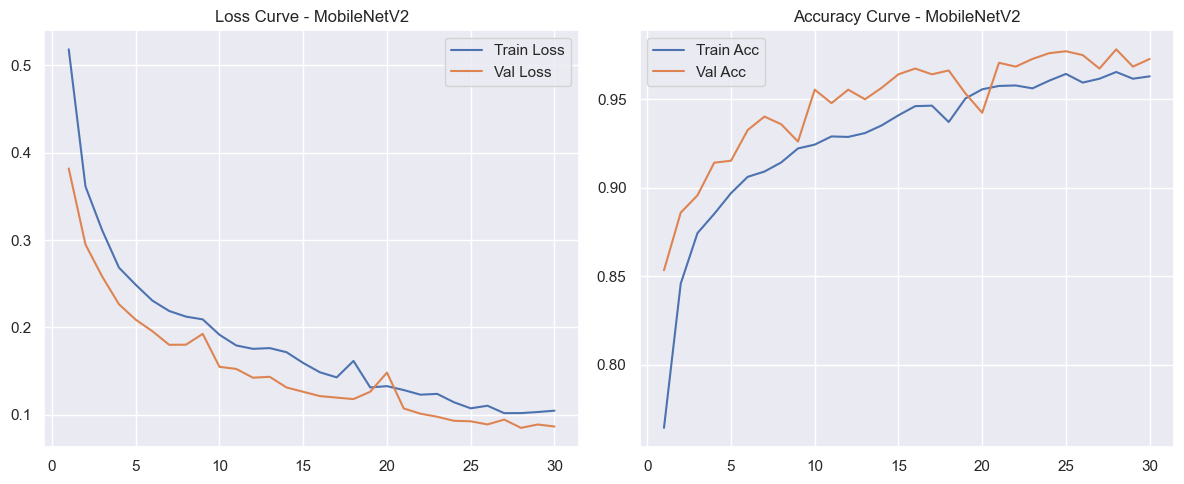

In [89]:
import seaborn as sns
import matplotlib.pyplot as plt

epochs = params_train_mobilenet["epochs"]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.lineplot(x=range(1, epochs + 1), y=loss_hist_mobile["train"], ax=ax[0], label="Train Loss")
sns.lineplot(x=range(1, epochs + 1), y=loss_hist_mobile["val"], ax=ax[0], label="Val Loss")
ax[0].set_title("Loss Curve - MobileNetV2")

sns.lineplot(x=range(1, epochs + 1), y=metric_hist_mobile["train"], ax=ax[1], label="Train Acc")
sns.lineplot(x=range(1, epochs + 1), y=metric_hist_mobile["val"], ax=ax[1], label="Val Acc")
ax[1].set_title("Accuracy Curve - MobileNetV2")

plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

 Brain Tumor       0.98      0.98      0.98       503
     Healthy       0.98      0.97      0.98       418

    accuracy                           0.98       921
   macro avg       0.98      0.98      0.98       921
weighted avg       0.98      0.98      0.98       921



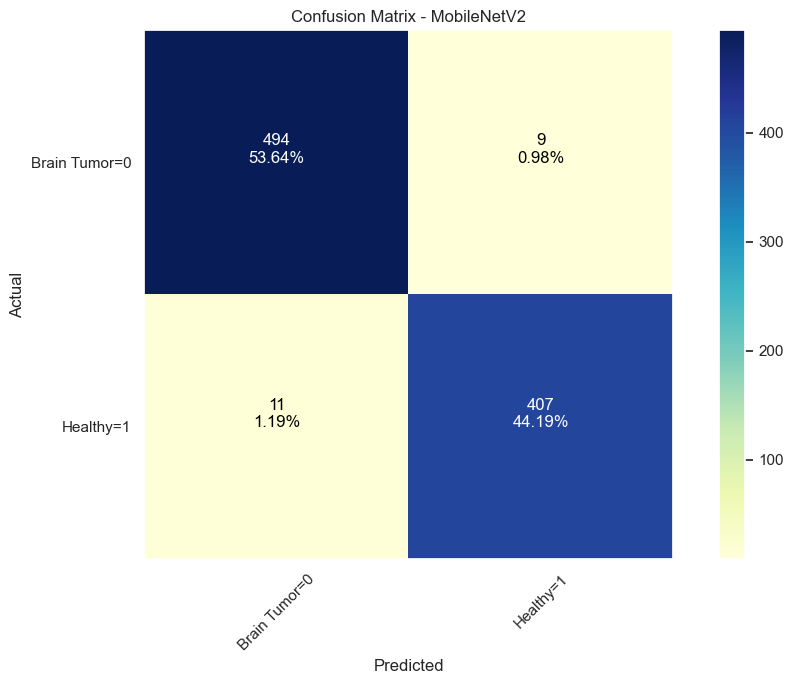

In [90]:
from sklearn.metrics import classification_report, confusion_matrix

# Predict true and predicted labels
y_true_mob, y_pred_mob = True_and_Pred(val_loader, mobilenet)

# Classification report
print(classification_report(y_true_mob, y_pred_mob, target_names=["Brain Tumor", "Healthy"]))

# Confusion matrix
cm_mobilenet = confusion_matrix(y_true_mob, y_pred_mob)

# Show confusion matrix
show_confusion_matrix(cm_mobilenet, CLA_label, title="Confusion Matrix - MobileNetV2")


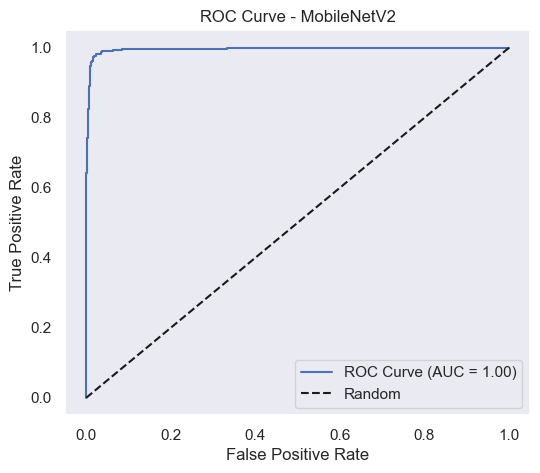

In [91]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_true, y_pred, y_scores = True_Pred_Scores(val_loader, mobilenet)

fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - MobileNetV2')
plt.legend()
plt.grid()
plt.show()


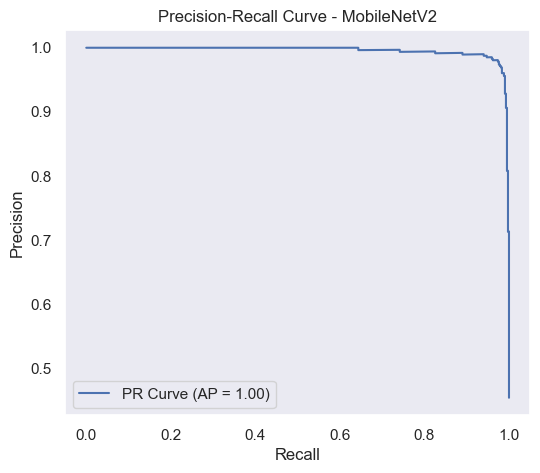

In [92]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(y_true, y_scores)
ap = average_precision_score(y_true, y_scores)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f'PR Curve (AP = {ap:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - MobileNetV2')
plt.legend()
plt.grid()
plt.show()


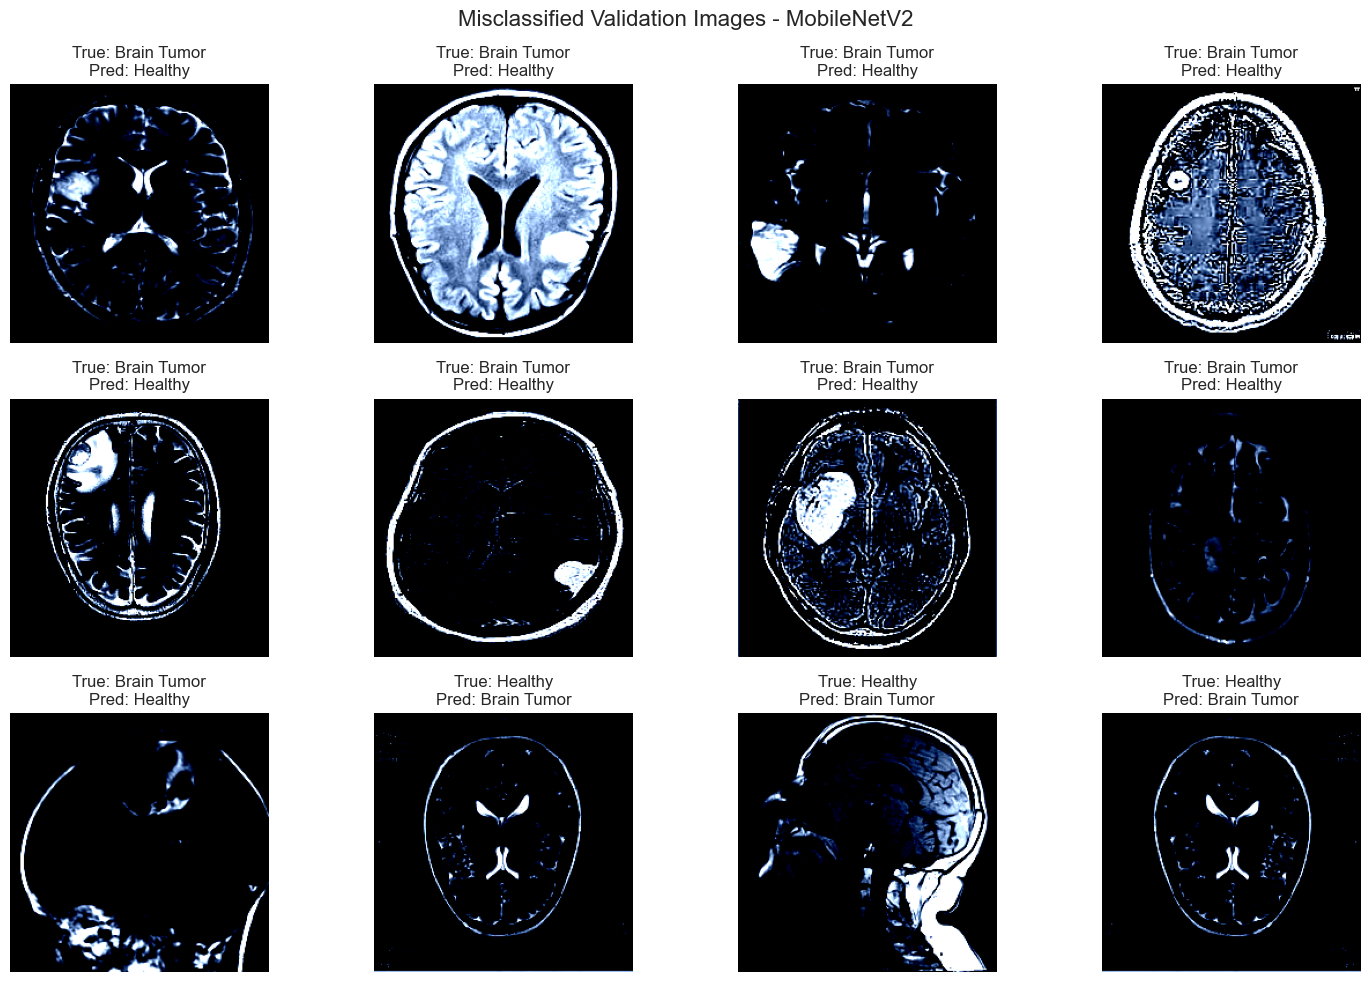

In [93]:
misclassified_mob = get_misclassified_images(val_loader, mobilenet, val_dataset, CLA_label)

plt.figure(figsize=(15, 10))
for idx in range(min(12, len(misclassified_mob))):
    img_tensor, true_label, pred_label, img_path = misclassified_mob[idx]
    img_np = img_tensor.numpy().transpose((1, 2, 0))
    img_valid = np.clip(img_np, 0, 1)

    plt.subplot(3, 4, idx + 1)
    plt.imshow(img_valid)
    plt.title(f"True: {CLA_label[true_label]}\nPred: {CLA_label[pred_label]}")
    plt.axis('off')

plt.suptitle("Misclassified Validation Images - MobileNetV2", fontsize=16)
plt.tight_layout()
plt.show()


In [94]:
torch.save(mobilenet.state_dict(), "mobilenet_brain.pt")


In [95]:
# --- MobileNetV2 Metrics ---
y_true_mob, y_pred_mob, y_scores_mob = True_Pred_Scores(val_loader, mobilenet)
acc_mob = accuracy_score(y_true_mob, y_pred_mob)
f1_mob = f1_score(y_true_mob, y_pred_mob)
precision_mob = precision_score(y_true_mob, y_pred_mob)
recall_mob = recall_score(y_true_mob, y_pred_mob)
auc_mob = auc(*roc_curve(y_true_mob, y_scores_mob)[:2])
ap_mob = average_precision_score(y_true_mob, y_scores_mob)

# --- Updated DataFrame ---
comparison_df = pd.DataFrame({
    "Model": ["CNN", "ResNet18", "MobileNetV2"],
    "Accuracy": [acc_cnn, acc_resnet, acc_mob],
    "F1-Score": [f1_cnn, f1_resnet, f1_mob],
    "Precision": [precision_cnn, precision_resnet, precision_mob],
    "Recall (Sensitivity)": [recall_cnn, recall_resnet, recall_mob],
    "AUC (ROC)": [auc_cnn, auc_resnet, auc_mob],
    "Average Precision (PR)": [ap_cnn, ap_resnet, ap_mob]
})

# Display nicely
print(tabulate(comparison_df, headers='keys', tablefmt='github'))


NameError: name 'acc_cnn' is not defined

Stream lit